# PHYS 575 — Gravitational-Wave Dataset Exploration
### Four-class classification of two-channel gravitational-wave detector strain

**Team:** Daniel Fredin, Glen "Bubba" Chung, and Tyler Grabarczyk  
**Dataset:** `GW2_Andy.h5`  
**Project:** *Comparison of STFT and Q-transform representations for CNN-based classification*

## Objective

The goal is to explore a labeled dataset containing one-second detector strain segments and assess its suitability for a four-class convolutional neural network (CNN). The categories are **background**, **binary black hole (BBH)**, **core-collapse supernova (CCSN)**, and **glitch**.

This notebook examines the HDF5 structure, signal quality, amplitude distributions, relationships between the two detector channels, and time-frequency representations. It also defines a reproducible data partition and outlines the proposed classification experiment.

The analysis uses the supplied observations directly, without modifying the source file or training a neural network. Numerical findings are based on this dataset; its acquisition and processing history are not provided.

## 0. Setup and reproducibility

Install dependencies from the project directory:

```bash
python -m pip install -r requirements.txt
```

Open this notebook in VS Code or Jupyter and select the Python environment where the packages are installed. Put `GW2_Andy.h5` in the `data/` folder, beside the notebook, or specify its location using the `GW2_DATA_PATH` environment variable. The file is excluded from Git because it exceeds GitHub's standard file-size limit.

**Dataset assumptions.** The accompanying course presentation specifies a sampling frequency of 4096 Hz and one-second clips. The HDF5 file does not contain detector names, timestamps, injection details, or a preprocessing record. The channels are therefore called *Detector 0* and *Detector 1* throughout this notebook. Their physical identities and absolute timing cannot be verified from these arrays alone.

In [1]:
import os
import sys
from pathlib import Path
import hashlib

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
FS = 4096  # Hz; specified in the course dataset presentation
CLASS_NAMES = ('background', 'binaryblackhole', 'ccsn', 'glitch')
CLASS_LABELS = ('Background', 'BBH', 'CCSN', 'Glitch')
LABEL_MAP = {name: i for i, name in enumerate(CLASS_NAMES)}
SAMPLE_INDEX = 0  # same index for each class, as in the supplied example screenshots
SAVE_FIGURES = False  # turn on to export PNGs into figures/

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 105, 'axes.grid': False})

project_dir = Path.cwd()
preferred = os.environ.get('GW2_DATA_PATH')
candidates = [Path(preferred).expanduser()] if preferred else []
candidates += [
    project_dir / 'data' / 'GW2_Andy.h5',
    project_dir / 'GW2_Andy.h5',
    project_dir.parent / 'data' / 'GW2_Andy.h5',
]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    tried = '\n'.join('  - ' + str(p) for p in candidates)
    raise FileNotFoundError(
        'Cannot find GW2_Andy.h5. Put it in GW2_CBC/data/ or set GW2_DATA_PATH.\n'
        + tried
    )

print(f'Python: {sys.version.split()[0]}')
print(f'Working directory: {project_dir}')
print(f'HDF5 file: {DATA_PATH}')
print(f'File size: {DATA_PATH.stat().st_size / 2**20:.1f} MiB')

def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        out = project_dir / 'figures'
        out.mkdir(exist_ok=True)
        fig.savefig(out / name, dpi=160, bbox_inches='tight')
    plt.show()

Python: 3.10.22
Working directory: /mnt/d/OneDrive/Desktop/UW Autumn 2026/PHYS 575/final_project/GW2_CBC
HDF5 file: /mnt/d/OneDrive/Desktop/UW Autumn 2026/PHYS 575/final_project/GW2_CBC/data/GW2_Andy.h5
File size: 256.0 MiB


## 1. Understanding the data

### 1a. Structure and class distribution

The HDF5 file organizes the data into four labeled groups. We verify the actual number of records, array shapes, and data types before analyzing individual observations. Each example is stored as `(detectors, samples)`.

In [2]:
with h5py.File(DATA_PATH, 'r') as h5:
    found = list(h5.keys())
    if set(found) != set(CLASS_NAMES):
        raise ValueError(f'Expected classes {CLASS_NAMES}, found {found}')
    summary = []
    for key in CLASS_NAMES:
        d = h5[key]
        summary.append({
            'Class': key,
            'Examples': len(d),
            'Shape': str(tuple(d.shape)),
            'dtype': str(d.dtype),
            'HDF5 attributes': len(d.attrs),
        })
        assert d.ndim == 3 and d.shape[1] == 2 and d.shape[2] == FS, f'Unexpected shape for {key}: {d.shape}'
    assert len(h5.attrs) == 0, 'Unexpected root metadata (inspect this separately)'

structure_df = pd.DataFrame(summary)
display(structure_df)
TOTAL_EXAMPLES = int(structure_df['Examples'].sum())
print(f'Total examples: {TOTAL_EXAMPLES:,}')
print(f'Number of classes: {len(CLASS_NAMES)}')
print(f'Samples per detector: {FS}; duration: {FS / FS:.1f} s')
print('Root metadata: none')

,Class,Examples,Shape,dtype,HDF5 attributes
0,background,2048,"(2048, 2, 4096)",float32,0
1,binaryblackhole,2048,"(2048, 2, 4096)",float32,0
2,ccsn,2048,"(2048, 2, 4096)",float32,0
3,glitch,2048,"(2048, 2, 4096)",float32,0


Total examples: 8,192
Number of classes: 4
Samples per detector: 4096; duration: 1.0 s
Root metadata: none


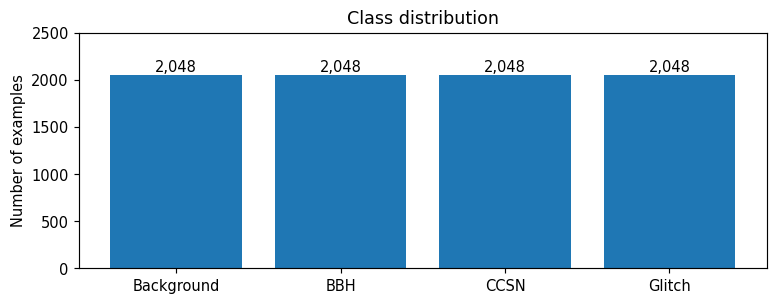

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.bar(CLASS_LABELS, structure_df['Examples'].values)
ax.set(title='Class distribution', ylabel='Number of examples', ylim=(0, 2500))
for i, n in enumerate(structure_df['Examples']):
    ax.text(i, n + 45, f'{n:,}', ha='center')
finish_figure(fig, '01_class_counts.png')

### 1b. Signal quality, amplitudes, and exact duplicates

We check for nonfinite values, effectively zero-valued clips, extreme sample amplitudes, and exact duplicate records. A typical strain amplitude of order unity is *consistent* with normalization, but it does not establish the whitening algorithm or processing history.

The summary statistics are computed in batches. Peaks are measured per two-channel clip; RMS is measured separately for each detector. Values are not clipped, removed, or modified in the original data.

In [4]:
BATCH_SIZE = 128
class_stats = {}
quality_rows = []
with h5py.File(DATA_PATH, 'r') as h5:
    for key in CLASS_NAMES:
        d = h5[key]
        peaks, rmss = [], []
        nonfinite_values = 0
        n_over_10 = 0
        n_over_100 = 0
        for start in range(0, len(d), BATCH_SIZE):
            chunk = np.asarray(d[start:start+BATCH_SIZE], dtype=np.float32)
            finite = np.isfinite(chunk)
            nonfinite_values += int((~finite).sum())
            if not finite.all():
                # Replace invalid values only in this temporary statistics array.
                chunk = np.where(finite, chunk, 0.0)
            peaks.append(np.max(np.abs(chunk), axis=(1, 2)))
            rmss.append(np.sqrt(np.mean(chunk.astype(np.float64)**2, axis=2)))
            n_over_10 += int((np.abs(chunk) > 10).sum())
            n_over_100 += int((np.abs(chunk) > 100).sum())
        peaks = np.concatenate(peaks)
        rmss = np.vstack(rmss)
        class_stats[key] = {'peak': peaks, 'rms': rmss}
        quality_rows.append({
            'Class': key,
            'Nonfinite values': nonfinite_values,
            'Median RMS': round(float(np.median(rmss)), 3),
            'Clips with peak > 10': int((peaks > 10).sum()),
            'Clips with peak > 100': int((peaks > 100).sum()),
            'Near-zero clips': int(np.sum(np.all(rmss < 1e-8, axis=1))),
            '99th percentile peak': round(float(np.percentile(peaks, 99)), 2),
            'Maximum peak': round(float(peaks.max()), 2),
            'Values |x| > 10': n_over_10,
            'Values |x| > 100': n_over_100,
        })
quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print('Note: high-amplitude observations are retained; their origin is not documented.')

,Class,Nonfinite values,Median RMS,Clips with peak > 10,Clips with peak > 100,Near-zero clips,99th percentile peak,Maximum peak,Values |x| > 10,Values |x| > 100
0,background,0,1.200,50,5,0,13.77,982.90,5917,580
1,binaryblackhole,0,1.264,62,2,0,14.16,754.83,2902,232
2,ccsn,0,1.254,52,1,0,14.01,646.13,2856,127
3,glitch,0,1.455,1383,7,0,37.86,4646.25,524870,1256


Note: high-amplitude observations are retained; their origin is not documented.


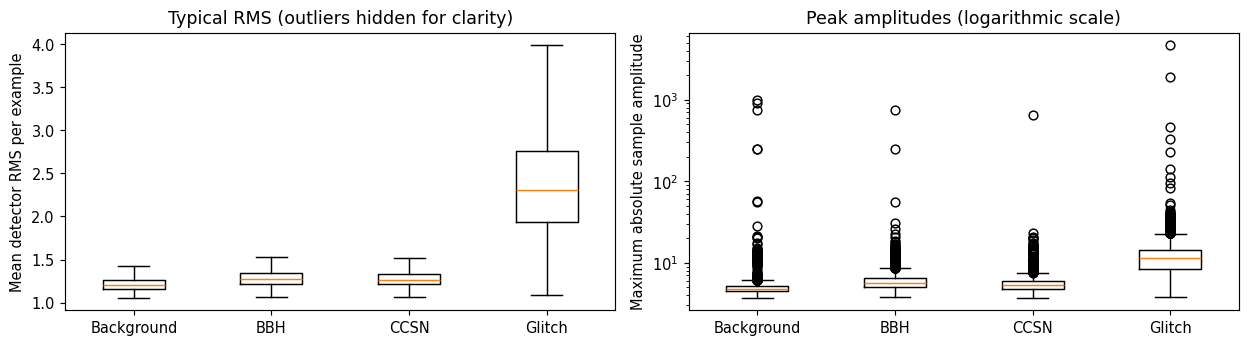

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
rms_data = [class_stats[key]['rms'].mean(axis=1) for key in CLASS_NAMES]
peak_data = [class_stats[key]['peak'] for key in CLASS_NAMES]
ax1.boxplot(rms_data, showfliers=False)
ax1.set_xticks(range(1, len(CLASS_LABELS) + 1), CLASS_LABELS)
ax1.set(ylabel='Mean detector RMS per example', title='Typical RMS (outliers hidden for clarity)')
ax2.boxplot(peak_data, showfliers=True)
ax2.set_xticks(range(1, len(CLASS_LABELS) + 1), CLASS_LABELS)
ax2.set(yscale='log', ylabel='Maximum absolute sample amplitude', title='Peak amplitudes (logarithmic scale)')
finish_figure(fig, '02_amplitude_quality.png')

In [6]:
# Exact, byte-for-byte duplicate detection; this does NOT identify near duplicates
# or repeated astrophysical templates injected into different noise realizations.
seen = set()
duplicate_counts = {}
with h5py.File(DATA_PATH, 'r') as h5:
    for key in CLASS_NAMES:
        duplicates = 0
        for start in range(0, len(h5[key]), BATCH_SIZE):
            chunk = h5[key][start:start+BATCH_SIZE]
            for example in chunk:
                digest = hashlib.blake2b(example.tobytes(), digest_size=16).digest()
                if digest in seen:
                    duplicates += 1
                else:
                    seen.add(digest)
        duplicate_counts[key] = duplicates
print('Exact duplicate records (within/across classes):', duplicate_counts)
print('Repeated templates with distinct noise cannot be excluded without injection metadata.')

Exact duplicate records (within/across classes): {'background': 0, 'binaryblackhole': 0, 'ccsn': 0, 'glitch': 0}
Repeated templates with distinct noise cannot be excluded without injection metadata.


### 1c. Example waveforms from both detectors

For each class, plot the same row index in both channels. The horizontal axis measures elapsed time within the one-second segment, rather than a verified absolute GPS time. Individual examples illustrate morphology but cannot establish how typical an event is for its class.

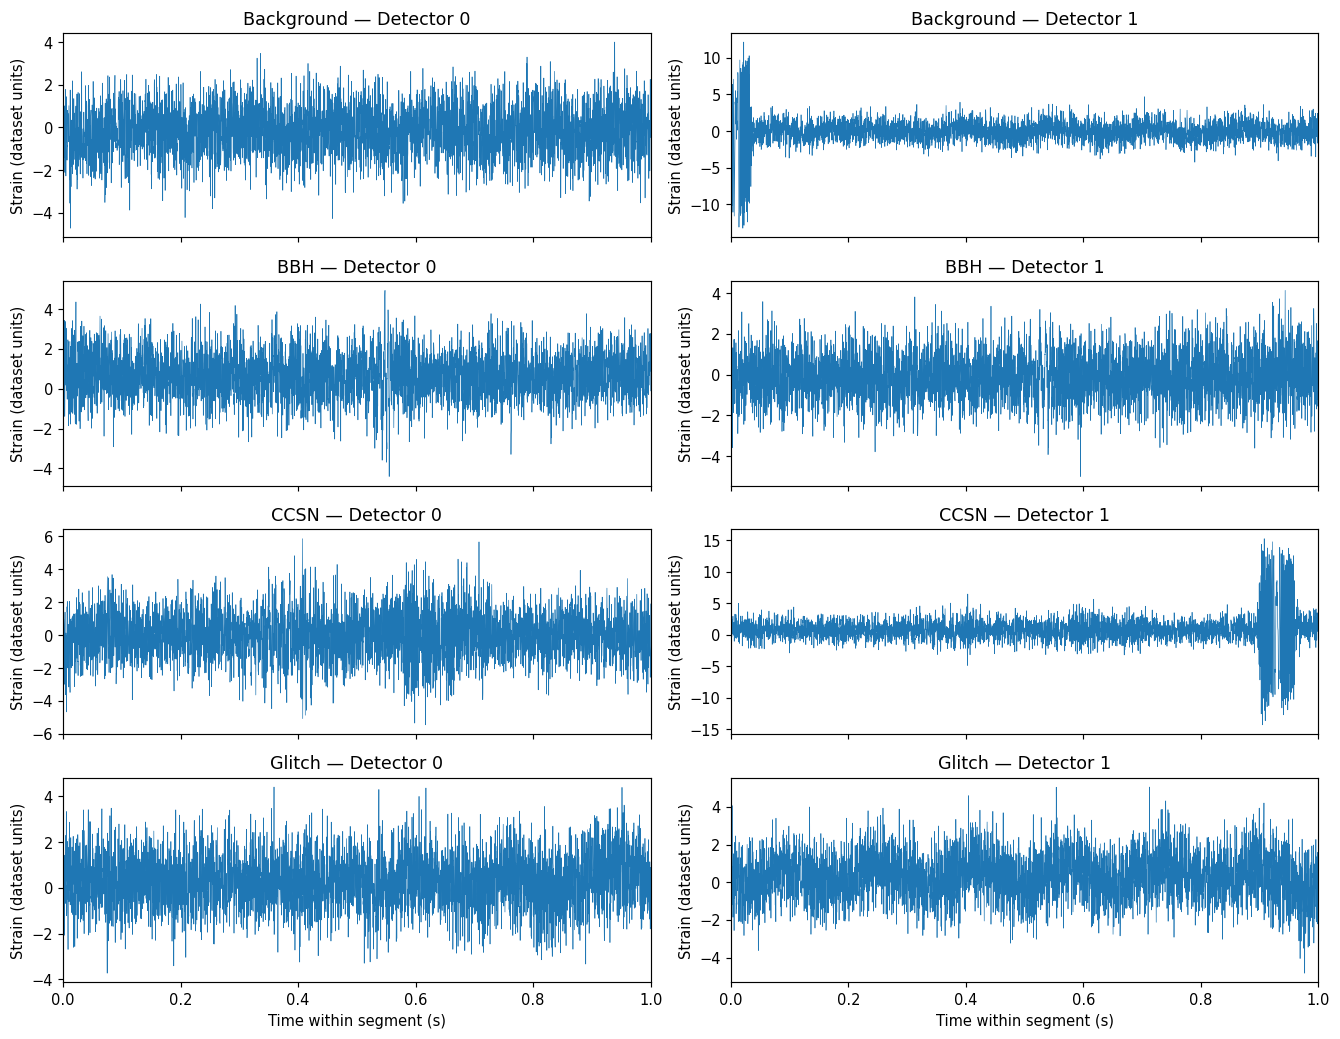

In [7]:
examples = {}
with h5py.File(DATA_PATH, 'r') as h5:
    for key in CLASS_NAMES:
        examples[key] = np.asarray(h5[key][SAMPLE_INDEX], dtype=np.float32)

t = np.arange(FS) / FS
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharex=True)
for r, key in enumerate(CLASS_NAMES):
    for ch in range(2):
        axes[r, ch].plot(t, examples[key][ch], linewidth=0.45)
        axes[r, ch].set(title=f'{CLASS_LABELS[r]} — Detector {ch}', ylabel='Strain (dataset units)', xlim=(0, 1))
        if r == 3:
            axes[r, ch].set_xlabel('Time within segment (s)')
finish_figure(fig, '03_example_waveforms.png')

### 1d. Relationship between the detector channels

A shared astrophysical transient may produce changes in the signal energy in two detectors. We compute Pearson correlation between short-time RMS *envelopes* to explore that possibility, without requiring point-by-point agreement between the rapidly oscillating strain series.

These correlations are descriptive. They do not establish detector coincidence, source origin, relative calibration, or exact synchronization.

,Class,Median RMS-envelope correlation,10th percentile,90th percentile
0,Background,0.144,-0.066,0.347
1,BBH,0.478,0.128,0.792
2,CCSN,0.303,0.037,0.666
3,Glitch,0.077,-0.157,0.393


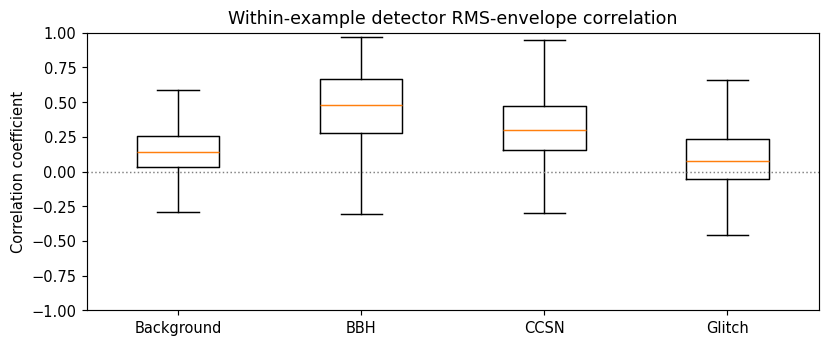

In [8]:
WINDOW_SAMPLES = 64  # 15.625 ms non-overlapping RMS windows
assert FS % WINDOW_SAMPLES == 0

def envelope_correlation(batch):
    # batch shape (N, 2, 4096)
    x = batch.reshape(len(batch), 2, FS // WINDOW_SAMPLES, WINDOW_SAMPLES)
    env = np.sqrt(np.mean(x.astype(np.float64)**2, axis=-1))
    u = env[:, 0] - np.mean(env[:, 0], axis=1, keepdims=True)
    v = env[:, 1] - np.mean(env[:, 1], axis=1, keepdims=True)
    denom = np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1)
    return np.divide(np.sum(u*v, axis=1), denom, out=np.zeros(len(batch)), where=denom > 0)

corr_by_class = {}
with h5py.File(DATA_PATH, 'r') as h5:
    for key in CLASS_NAMES:
        corr_by_class[key] = np.concatenate([
            envelope_correlation(np.asarray(h5[key][start:start+BATCH_SIZE]))
            for start in range(0, len(h5[key]), BATCH_SIZE)
        ])

corr_df = pd.DataFrame({
    'Class': CLASS_LABELS,
    'Median RMS-envelope correlation': [round(float(np.median(corr_by_class[key])), 3) for key in CLASS_NAMES],
    '10th percentile': [round(float(np.percentile(corr_by_class[key], 10)), 3) for key in CLASS_NAMES],
    '90th percentile': [round(float(np.percentile(corr_by_class[key], 90)), 3) for key in CLASS_NAMES],
})
display(corr_df)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([corr_by_class[key] for key in CLASS_NAMES], showfliers=False)
ax.set_xticks(range(1, len(CLASS_LABELS) + 1), CLASS_LABELS)
ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.set(title='Within-example detector RMS-envelope correlation', ylabel='Correlation coefficient', ylim=(-1, 1))
finish_figure(fig, '04_detector_envelope_correlation.png')

### 1e. Frequency content and possible preprocessing

Welch power spectral density (PSD) estimates show the distribution of power across frequency. We use a reproducible random subset of examples from each class to avoid relying on the ordering of the HDF5 records.

The broadband spectral floor is relatively flat, but distinct narrowband peaks and class-dependent features remain. This pattern may be consistent with whitening or another normalization procedure, **but the file does not document its processing history**. We therefore do not re-whiten the data as part of this exploratory analysis.

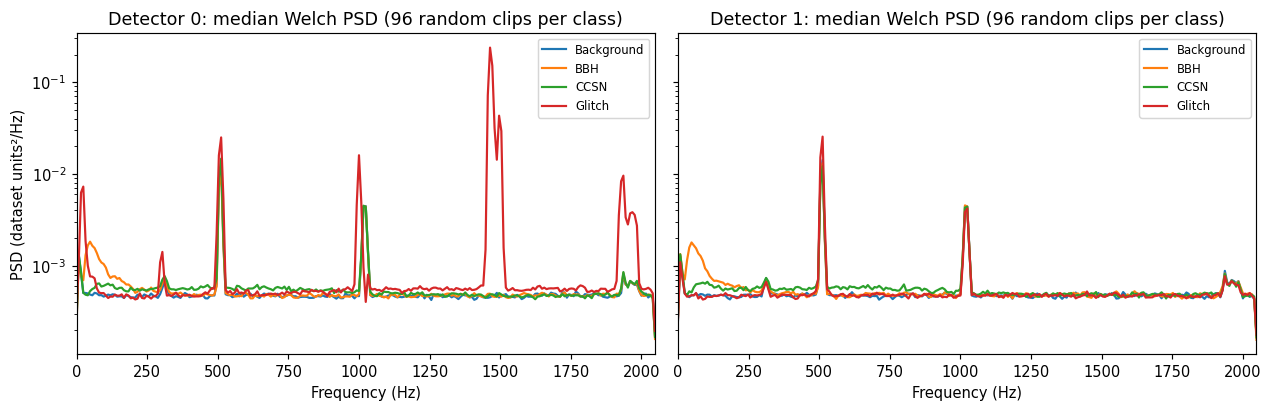

In [9]:
PSD_EXAMPLES = 96  # random records per class; fixed seed for reproducibility
psd_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
with h5py.File(DATA_PATH, 'r') as h5:
    for key, label in zip(CLASS_NAMES, CLASS_LABELS):
        record_ids = np.sort(psd_rng.choice(len(h5[key]), size=PSD_EXAMPLES, replace=False))
        data = np.asarray(h5[key][record_ids], dtype=np.float32)
        for ch in range(2):
            f, pxx = signal.welch(data[:, ch, :], fs=FS, nperseg=512,
                                  noverlap=256, axis=-1)
            median_psd = np.median(pxx, axis=0)
            axes[ch].semilogy(f, np.maximum(median_psd, 1e-20), label=label)
for ch, ax in enumerate(axes):
    ax.set(xlim=(0, FS/2), xlabel='Frequency (Hz)',
           title=f'Detector {ch}: median Welch PSD (96 random clips per class)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('PSD (dataset units²/Hz)')
figures_dir = project_dir / 'figures'
if SAVE_FIGURES:
    figures_dir.mkdir(exist_ok=True)
    fig.savefig(figures_dir / '05_median_psd.png', dpi=160, bbox_inches='tight')
plt.show()

### 1f. Short-Time Fourier Transform (STFT)

The STFT maps each strain segment into a two-dimensional time-frequency image using a fixed-length analysis window. Here we use a 512-sample Hann window and 448-sample overlap. **Zero-padding at the boundaries** retains coverage near the first and last samples, but transformed features there should be interpreted with care.

For display, each panel uses the same color range selected from the collection of example spectrograms; no samples in the HDF5 file are altered. The model's eventual input scaling will be determined using training data only.

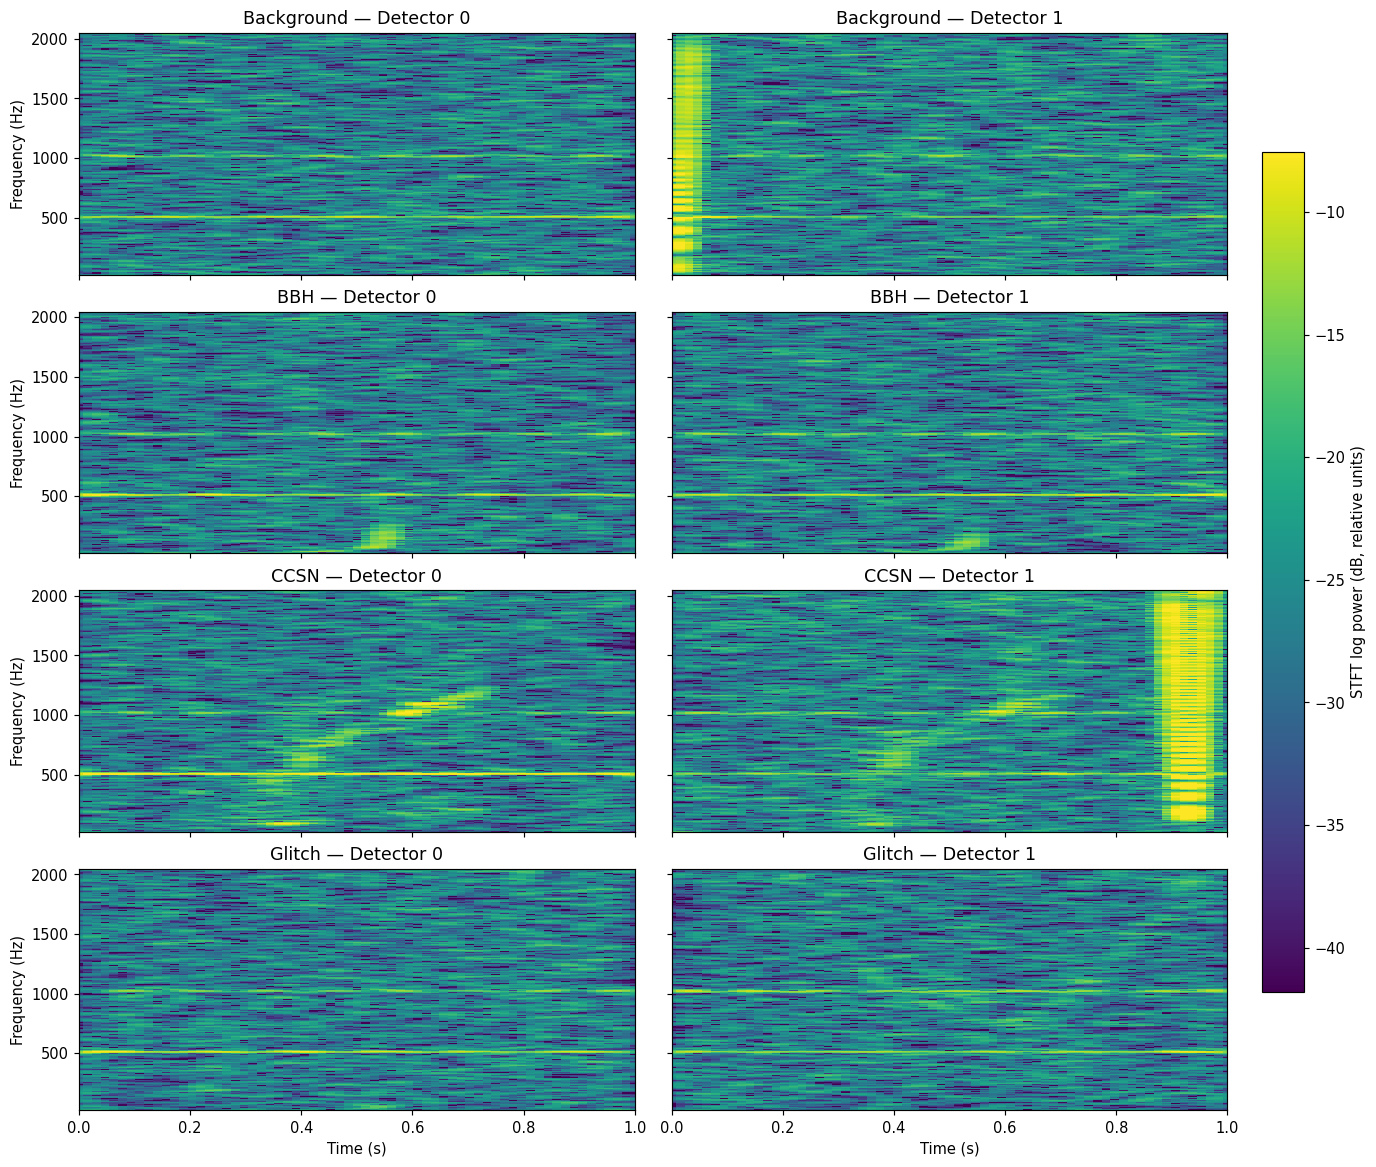

STFT shape (frequency bins × time bins): (257, 65)
Example plotting range: -41.8 to -7.5 dB


In [10]:
STFT_NPERSEG = 512
STFT_NOVERLAP = 448

def stft_log_power(x):
    frequencies, times, stft_values = signal.stft(
        x, fs=FS, window='hann', nperseg=STFT_NPERSEG,
        noverlap=STFT_NOVERLAP, boundary='zeros', padded=True,
    )
    power_db = 10 * np.log10(np.maximum(np.abs(stft_values)**2, 1e-12))
    return frequencies, times, power_db

stft_examples = {}
for key in CLASS_NAMES:
    for ch in range(2):
        stft_examples[(key, ch)] = stft_log_power(examples[key][ch])

# One color scale for all eight plotted examples (visualization only).
all_stft_db = np.concatenate([result[2].ravel() for result in stft_examples.values()])
stft_vmin, stft_vmax = np.percentile(all_stft_db, [2, 99.5])
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True, sharey=True,
                         layout='constrained')
for r, key in enumerate(CLASS_NAMES):
    for ch in range(2):
        frequencies, times, power_db = stft_examples[(key, ch)]
        mesh = axes[r, ch].pcolormesh(times, frequencies, power_db,
                                     shading='auto', cmap='viridis',
                                     vmin=stft_vmin, vmax=stft_vmax)
        axes[r, ch].set(title=f'{CLASS_LABELS[r]} — Detector {ch}',
                        ylim=(20, FS/2), xlim=(0, 1))
        if ch == 0:
            axes[r, ch].set_ylabel('Frequency (Hz)')
        if r == 3:
            axes[r, ch].set_xlabel('Time (s)')
fig.colorbar(mesh, ax=axes, shrink=0.78, pad=0.02,
             label='STFT log power (dB, relative units)')
if SAVE_FIGURES:
    figures_dir.mkdir(exist_ok=True)
    fig.savefig(figures_dir / '06_stft_examples.png', dpi=160, bbox_inches='tight')
plt.show()
print('STFT shape (frequency bins × time bins):', power_db.shape)
print(f'Example plotting range: {stft_vmin:.1f} to {stft_vmax:.1f} dB')

### 1g. Q-transform: initial time-frequency preview

The Q-transform uses variable time-frequency resolution, making it an alternative representation for transient gravitational-wave signals. GWpy's multi-Q method is applied with **`whiten=False`**, since the file contains only one-second clips and no supplied noise ASD for a reliable whitening operation.

For this preview, `frange=(40, 1024)` Hz and `qrange=(4, 8)` are exploratory choices. Crucially, with `logf=False`, GWpy interprets **`fres` as frequency spacing in Hz**, not as a number of bins. We use `fres=8.0` Hz here. We also use `norm=False` to avoid per-example median normalization at this exploratory stage.

This figure displays both channels of the same four examples. Q-transform and STFT values have **different numerical meanings and color scales**; they are not directly comparable pixel by pixel. Neither preview establishes which method will be the better classifier. Frequency limits, image shape, and consistent model preprocessing must be settled in the training experiment.

GWpy reference: https://gwpy.readthedocs.io/en/stable/reference/gwpy.timeseries.TimeSeries/

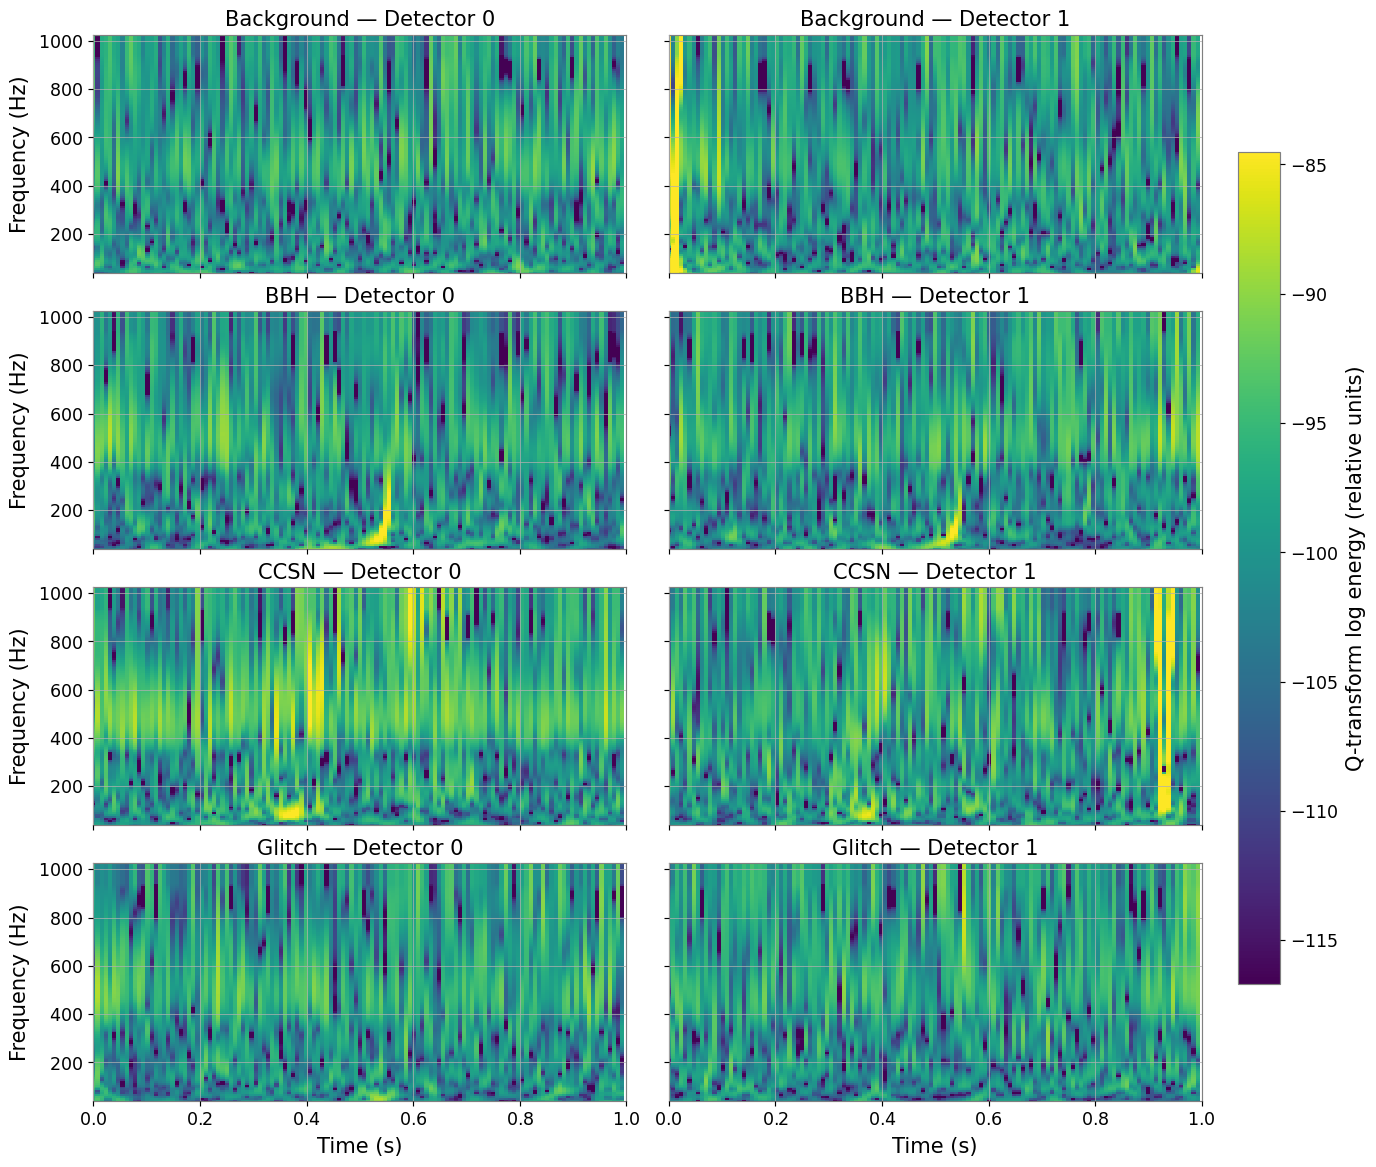

Q-transform previews completed: 8/8
Example Q-transform array shape (frequency × time): (123, 128)


In [11]:
try:
    from gwpy.timeseries import TimeSeries
except ImportError:
    TimeSeries = None
    print('Optional Q-transform preview unavailable: GWpy is not installed in this kernel.')
    print('Install the project requirements and rerun this cell to enable Q-transform plots.')

if TimeSeries is not None:
    Q_RANGE = (4, 8)
    Q_FREQUENCIES = (40, 1024)  # Hz; initial preview range
    Q_FREQUENCY_STEP_HZ = 8.0    # fres is in Hz when logf=False
    Q_TIME_STEP_S = 1 / 128
    q_examples = {}
    for key in CLASS_NAMES:
        for ch in range(2):
            try:
                trace = TimeSeries(examples[key][ch], sample_rate=FS, t0=0)
                qgram = trace.q_transform(
                    whiten=False, qrange=Q_RANGE, frange=Q_FREQUENCIES,
                    tres=Q_TIME_STEP_S, fres=Q_FREQUENCY_STEP_HZ,
                    logf=False, norm=False,
                )
                q_values = np.asarray(qgram.value)
                q_times = np.asarray(qgram.times.value)
                q_freqs = np.asarray(qgram.frequencies.value)
                if q_values.shape == (len(q_times), len(q_freqs)):
                    q_values = q_values.T
                elif q_values.shape != (len(q_freqs), len(q_times)):
                    raise ValueError(f'Unexpected Q-transform shape: {q_values.shape}')
                q_log_energy = 10 * np.log10(np.maximum(q_values, 1e-12))
                q_examples[(key, ch)] = (q_freqs, q_times, q_log_energy)
            except Exception as exc:
                print(f'Q-transform preview failed: {key}, Detector {ch}: '
                      f'{type(exc).__name__}: {exc}')

    if q_examples:
        q_db = np.concatenate([item[2].ravel() for item in q_examples.values()])
        q_vmin, q_vmax = np.percentile(q_db, [2, 99.5])
        fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True,
                                 sharey=True, layout='constrained')
        for r, key in enumerate(CLASS_NAMES):
            for ch in range(2):
                ax = axes[r, ch]
                if (key, ch) in q_examples:
                    freqs, times, q_log_energy = q_examples[(key, ch)]
                    mesh = ax.pcolormesh(times, freqs, q_log_energy,
                                         shading='auto', cmap='viridis',
                                         vmin=q_vmin, vmax=q_vmax)
                else:
                    ax.text(0.5, 0.5, 'Transform unavailable',
                            transform=ax.transAxes, ha='center', va='center')
                ax.set(title=f'{CLASS_LABELS[r]} — Detector {ch}',
                       xlim=(0, 1), ylim=Q_FREQUENCIES)
                if ch == 0:
                    ax.set_ylabel('Frequency (Hz)')
                if r == 3:
                    ax.set_xlabel('Time (s)')
        fig.colorbar(mesh, ax=axes, shrink=0.78, pad=0.02,
                     label='Q-transform log energy (relative units)')
        if SAVE_FIGURES:
            figures_dir.mkdir(exist_ok=True)
            fig.savefig(figures_dir / '07_qtransform_preview.png',
                        dpi=160, bbox_inches='tight')
        plt.show()
        print(f'Q-transform previews completed: {len(q_examples)}/8')
        print('Example Q-transform array shape (frequency × time):',
              next(iter(q_examples.values()))[2].shape)
    else:
        print('No Q-transform previews were generated. Check the printed errors.')

## 2. Understanding the classification task

### 2a. Input data and target labels

Each input is a two-channel one-second strain segment, stored as a `float32` array with shape `(2, 4096)`. Its label identifies one of four classes:

| Label | HDF5 dataset | Interpretation |
|---:|---|---|
| 0 | `background` | Background detector data |
| 1 | `binaryblackhole` | Binary black hole (BBH) signal |
| 2 | `ccsn` | Core-collapse supernova (CCSN) signal |
| 3 | `glitch` | Non-astrophysical detector glitch |

The dataset keys provide labels but not waveform templates, injection parameters, source IDs, or detector noise provenance. Label correctness and the exact data-generation process cannot be established from the HDF5 content alone.

### 2b. Motivation

Gravitational-wave searches require distinguishing potential astrophysical transients from noise and instrumental artifacts. BBH and CCSN signals may have different time-frequency structures, while glitches can mimic short-duration events. This dataset provides a controlled four-class classification task; a trained model would not automatically constitute a validated detection pipeline for real observations.

### 2c. Success criteria

For the subsequent CNN experiment, we will evaluate accuracy, macro-averaged F1 score, precision and recall for each class, and a held-out confusion matrix. The validation set will guide development; the test split will be reserved for the final comparison. Since the labels are balanced, a class-frequency-only predictor is expected to achieve about 25% accuracy.

## 3. Experimental plan

### 3a. Reproducible train/validation/test split and baseline

The data do not include an official training partition. We create one reproducible **stratified 70% / 15% / 15% split** at the clip level and use the same examples for both representations. The row-index mapping is preserved so a record is never accidentally paired with another class during conversion.

The majority-class `DummyClassifier` is a sanity-check baseline only: it does not examine strain. A class-balanced dataset should yield roughly 25% accuracy. **If waveforms are derived from shared simulated templates, random clip-level splitting may overestimate generalization; the available HDF5 metadata are insufficient to verify template independence.**

In [12]:
with h5py.File(DATA_PATH, 'r') as h5:
    y = np.concatenate([
        np.full(len(h5[key]), label_id, dtype=np.int64)
        for label_id, key in enumerate(CLASS_NAMES)
    ])
all_indices = np.arange(len(y))
train_idx, holdout_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, stratify=y
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED, stratify=y[holdout_idx]
)
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(y)

split_table = pd.DataFrame({
    'Class': CLASS_LABELS,
    'Train': [np.sum(y[train_idx] == i) for i in range(4)],
    'Validation': [np.sum(y[val_idx] == i) for i in range(4)],
    'Test': [np.sum(y[test_idx] == i) for i in range(4)],
})
display(split_table)
print(f'Total: train {len(train_idx):,}, validation {len(val_idx):,}, test {len(test_idx):,}')

# The dataset is deliberately not loaded; DummyClassifier ignores features.
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(np.zeros((len(train_idx), 1)), y[train_idx])
baseline_pred = baseline.predict(np.zeros((len(val_idx), 1)))
print(f'Dummy validation accuracy: {accuracy_score(y[val_idx], baseline_pred):.3f}')
print(f'Dummy validation macro F1: {f1_score(y[val_idx], baseline_pred, average="macro", zero_division=0):.3f}')
print('Validation confusion matrix (rows=true, columns=predicted):')
display(pd.DataFrame(confusion_matrix(y[val_idx], baseline_pred, labels=range(4)),
                     index=CLASS_LABELS, columns=CLASS_LABELS))

,Class,Train,Validation,Test
0,Background,1433,307,308
1,BBH,1434,307,307
2,CCSN,1433,308,307
3,Glitch,1434,307,307


Total: train 5,734, validation 1,229, test 1,229
Dummy validation accuracy: 0.250
Dummy validation macro F1: 0.100
Validation confusion matrix (rows=true, columns=predicted):


,Background,BBH,CCSN,Glitch
Background,0,307,0,0
BBH,0,307,0,0
CCSN,0,308,0,0
Glitch,0,307,0,0


### 3b. Representation and CNN inputs

- **Original input:** two channels × 4096 strain samples per example.
- **STFT representation:** two log-power time-frequency maps stacked as CNN input channels.
- **Q-transform representation:** two time-frequency Q-energy maps stacked in the same order.
- **Target size:** tentatively `(2, 128, 128)` after deliberate resampling or interpolation; exact values will be documented and checked in the training workflow.
- **Output:** four class logits (one per HDF5 category); predicted label is the argmax.

We will not add a second whitening operation without reliable evidence that the supplied data require it. Visual intensity limits are chosen for figures only. For model inputs, any fitted normalization must use training examples alone; validation and test records cannot influence normalization or hyperparameter decisions.

### 3c. CNN architecture and training

Use one compact 2D CNN architecture with three convolutional blocks (Conv2D, ReLU, pooling), adaptive average pooling, and a four-class linear output. Train it separately with STFT and Q-transform inputs using an identical training recipe. Initial values: Adam optimizer, learning rate `1e-3`, batch size `64`, cross-entropy loss, and early stopping based on validation loss.

### 3d. Controlled comparison

Keep the train/validation/test indices, two-channel ordering, network architecture, training budget, optimizer, and metrics fixed. Match image dimensions and document differences in transform-specific normalization and frequency coverage. Compare test accuracy, macro F1, per-class recall, confusion matrices, and processing time.

### 3e. Limitations to track

- The preprocessing and whitening history is unknown; relatively flat spectra do not prove a specific whitening procedure.
- Narrow frequency peaks and large-amplitude events may create shortcuts unrelated to astrophysical morphology.
- Detector identity, timing offsets, simulation parameters, and event/template IDs are unavailable.
- Exact duplicate checking does not detect the reuse of waveforms embedded in different noise segments.
- Short clips limit low-frequency resolution and can produce boundary effects in both transformations.
- Q-transform and STFT outputs are different physical representations, so normalization and frequency limits must be described explicitly.

## 4. Conclusions

The supplied HDF5 file contains **8,192 balanced, two-channel observations**, with 4096 samples per channel at the stated 4096 Hz sampling rate. The exploratory checks find no nonfinite values or exact duplicate records, but the strain amplitudes have a long-tailed distribution, particularly for the glitch category. Differences in the median PSD and in short-time detector-envelope correlations indicate potentially useful class-dependent features.

The data appear normalized, and their broad frequency content is reasonably flat, but the absence of processing metadata prevents a definitive statement about whitening. Both the fixed-resolution STFT and variable-resolution Q-transform offer ways to represent transient structure as two-dimensional inputs; which method yields stronger classification performance is still an open empirical question.

**Planned classification experiment:** train and evaluate the same two-channel 2D CNN on STFT and Q-transform representations, using the same reproducible data partition and evaluation metrics. The central question is whether the choice of time-frequency representation changes four-class classification performance on this dataset.

**Libraries and references:** [h5py](https://docs.h5py.org/), [SciPy signal processing](https://docs.scipy.org/doc/scipy/reference/signal.html), [GWpy Q-transform](https://gwpy.readthedocs.io/en/stable/reference/gwpy.timeseries.TimeSeries/), and [scikit-learn](https://scikit-learn.org/).